# Mouhamed Cisse

In [47]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from keras.models import Sequential
import pandas as pd

In [48]:
import h5py

with h5py.File("Problem 2/train_happy.h5", "r") as f:
    print(list(f.keys()))
    X_train = f['train_set_x'][:]
    Y_train = f['train_set_y'][:]
with h5py.File("Problem 2/test_happy.h5", "r") as f:
    print(list(f.keys()))
    X_test = f['test_set_x'][:]
    Y_test = f['test_set_y'][:]

print("Train shape:", X_train.shape, Y_train.shape)
print("Test shape:", X_test.shape, Y_test.shape)

['list_classes', 'train_set_x', 'train_set_y']
['list_classes', 'test_set_x', 'test_set_y']
Train shape: (600, 64, 64, 3) (600,)
Test shape: (150, 64, 64, 3) (150,)


## 1

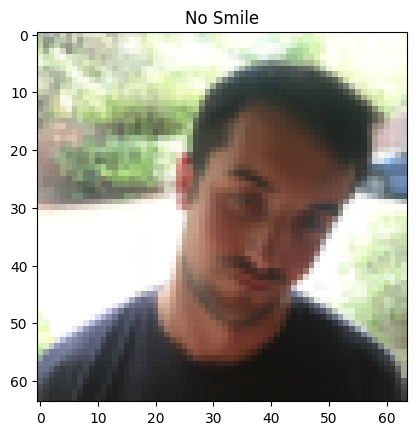

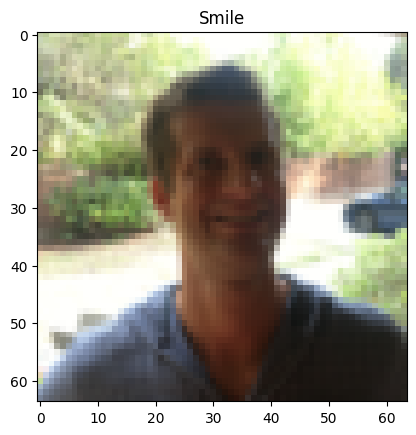

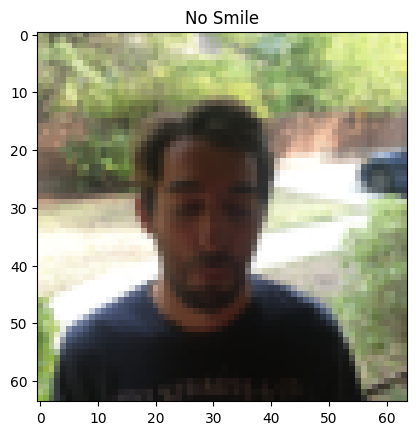

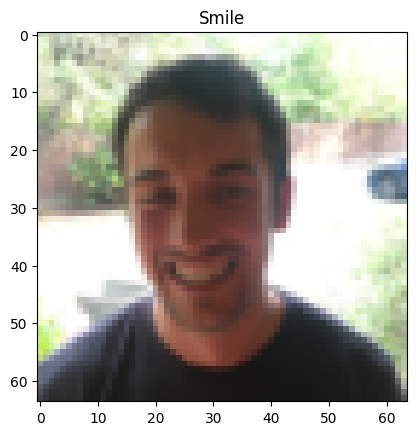

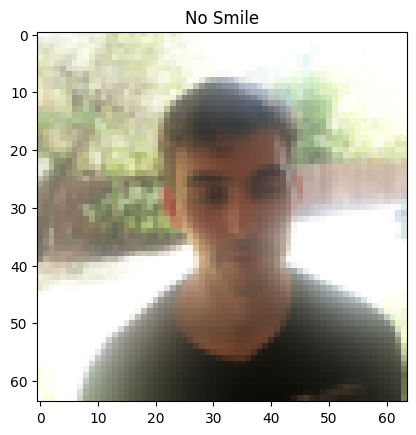

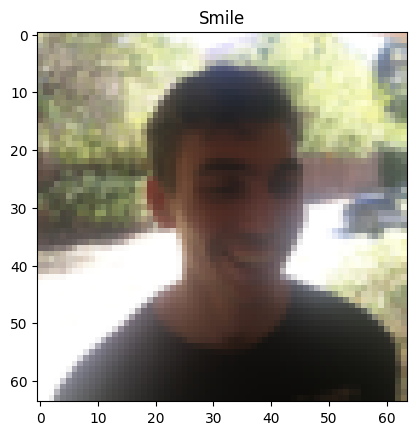

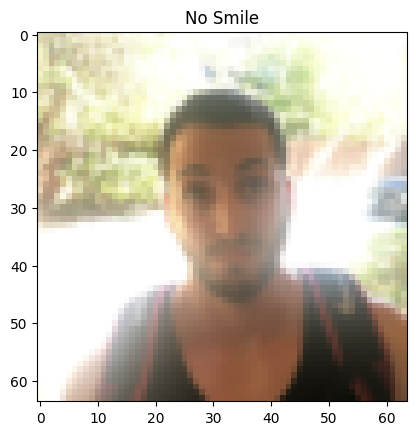

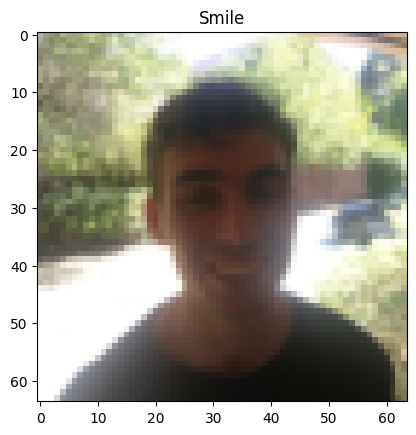

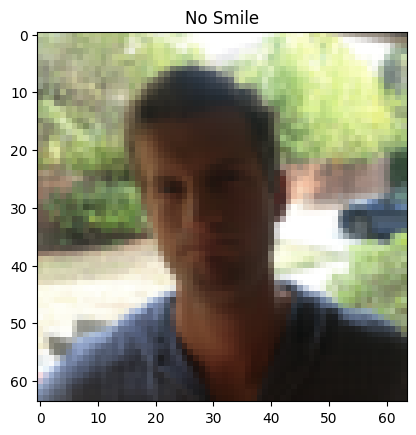

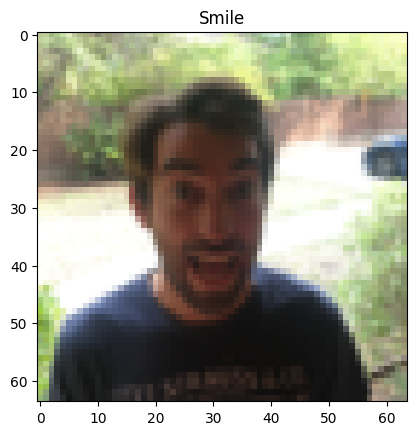

In [49]:
for i in range(5):
    i = np.argwhere(Y_train == 0)[i][0]
    j = np.argwhere(Y_train == 1)[i][0]
    plt.imshow(X_train[i])
    plt.title("No Smile")
    plt.show()
    plt.imshow(X_train[j])
    plt.title("Smile")
    plt.show()

## 2

In [50]:
smile, no_mile = np.bincount(Y_train.flatten())
print("Smile:", smile)
print("No Smile:", no_mile)

Smile: 300
No Smile: 300


The training dataset is perfectly balanced.

In [51]:
# Grayscaling and Normalization
from sklearn.utils import shuffle
X_train, y_train = shuffle(X_train, Y_train)
X_train_gray_norm = np.sum(X_train/3, axis=3, keepdims=True) / 255
X_test_gray_norm = np.sum(X_test/3, axis=3, keepdims=True) / 255

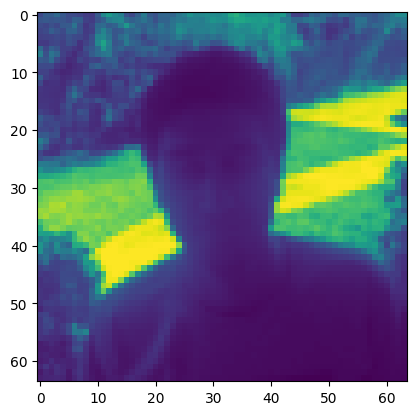

In [52]:
i = np.random.randint(0, len(X_train_gray_norm))
plt.imshow(X_train_gray_norm[i])
plt.show()

In [53]:
# Build the model
model = Sequential()
model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=(64,64,1)))
model.add(layers.MaxPooling2D(pool_size=(2,2)))

model.add(layers.Conv2D(128, (3,3), activation='relu'))
model.add(layers.AveragePooling2D(pool_size=(2,2)))


model.add(layers.Flatten())
model.add(layers.Dense(256, activation = 'relu'))
model.add(layers.Dense(2, activation = 'softmax'))
model.summary()

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_38 (Conv2D)              │ (None, 62, 62, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 29, 29, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_9             │ (None, 14, 14, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,497,794 (24.79 MB)

 Trainable params: 6,497,794 (24.79 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:
# parameterizing
model.compile("Adam",  loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

In [56]:
# training loop
history = model.fit(X_train_gray_norm,
                 y_train, 
                 batch_size = 500,
                 epochs = 20,
                 verbose = 1,
                 validation_data=(X_test_gray_norm, Y_test))

Epoch 1/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 286ms/step - accuracy: 0.6133 - loss: 0.6800 - val_accuracy: 0.6200 - val_loss: 0.6818
Epoch 2/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 258ms/step - accuracy: 0.6733 - loss: 0.6748 - val_accuracy: 0.7200 - val_loss: 0.6680
Epoch 3/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 287ms/step - accuracy: 0.7700 - loss: 0.6637 - val_accuracy: 0.7000 - val_loss: 0.6525
Epoch 4/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 262ms/step - accuracy: 0.6767 - loss: 0.6516 - val_accuracy: 0.7200 - val_loss: 0.6457
Epoch 5/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 258ms/step - accuracy: 0.8283 - loss: 0.6327 - val_accuracy: 0.7533 - val_loss: 0.6175
Epoch 6/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 252ms/step - accuracy: 0.7000 - loss: 0.6120 - val_accuracy: 0.6800 - val_loss: 0.6111
Epoch 7/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 262ms/step - accuracy: 0.7817 - loss: 0.5804 - val_accuracy: 0.6800 - val_loss: 0.5893
Epoch 8/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 303ms/step - accuracy: 0.7900 - loss: 0.5481 - val_accuracy: 0.7267 - val_loss:

# 3

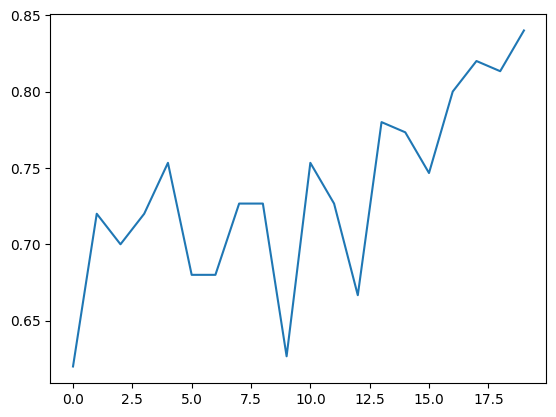

In [57]:
test_accuracy = history.history['val_accuracy']
plt.plot(np.arange(0, 20), test_accuracy)
plt.show()

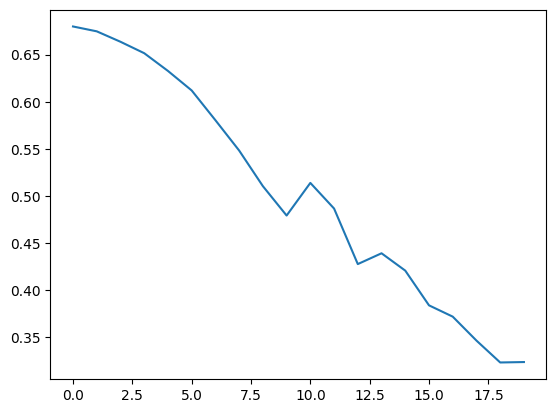

In [58]:
test_accuracy = history.history['loss']
plt.plot(np.arange(0, 20), test_accuracy)
plt.show()

In [60]:
# Test Accuracy
score = model.evaluate(X_test_gray_norm, Y_test)
print('Test Accuracy: {}'.format(score[1]))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8400 - loss: 0.3419
Test Accuracy: 0.8399999737739563


In [61]:
# additional epochs and hidden layers and MaxPooling instead of AveragePooling
# Build the model
model1 = Sequential()
model1.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=(64,64,1)))
model1.add(layers.MaxPooling2D(pool_size=(2,2)))

model1.add(layers.Conv2D(128, (3,3), activation='relu'))
model1.add(layers.MaxPooling2D(pool_size=(2,2)))

model1.add(layers.Conv2D(256, (3,3), activation='relu'))
model1.add(layers.MaxPooling2D(pool_size=(2,2)))


model1.add(layers.Flatten())
model1.add(layers.Dense(256, activation = 'relu'))
model1.add(layers.Dense(2, activation = 'softmax'))
model1.summary()

# parameterizing
model1.compile("Adam",  loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

# training loop
history = model1.fit(X_train_gray_norm,
                 y_train, 
                 batch_size = 500,
                 epochs = 30,
                 verbose = 1,
                 validation_data=(X_test_gray_norm, Y_test))

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_40 (Conv2D)              │ (None, 62, 62, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 29, 29, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_15 (Flatten)            │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,729,730 (10.41 MB)

 Trainable params: 2,729,730 (10.41 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 447ms/step - accuracy: 0.5133 - loss: 0.6967 - val_accuracy: 0.5600 - val_loss: 0.8234
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 350ms/step - accuracy: 0.5000 - loss: 0.8811 - val_accuracy: 0.6467 - val_loss: 0.6891
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 340ms/step - accuracy: 0.5917 - loss: 0.6899 - val_accuracy: 0.4467 - val_loss: 0.6934
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 317ms/step - accuracy: 0.5400 - loss: 0.6896 - val_accuracy: 0.5467 - val_loss: 0.6871
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 348ms/step - accuracy: 0.4983 - loss: 0.6888 - val_accuracy: 0.5600 - val_loss: 0.6825
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 322ms/step - accuracy: 0.5000 - loss: 0.6879 - val_accuracy: 0.5600 - val_loss: 0.6773
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 358ms/step - accuracy: 0.5000 - loss: 0.6850 - val_accuracy: 0.5533 - val_loss: 0.6732
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 356ms/step - accuracy: 0.5167 - loss: 0.6756 - val_accuracy: 0.6867 - val_loss:

In [62]:
# Test Accuracy
score = model1.evaluate(X_test_gray_norm, Y_test)
print('Test Accuracy: {}'.format(score[1]))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9067 - loss: 0.2028
Test Accuracy: 0.9066666960716248


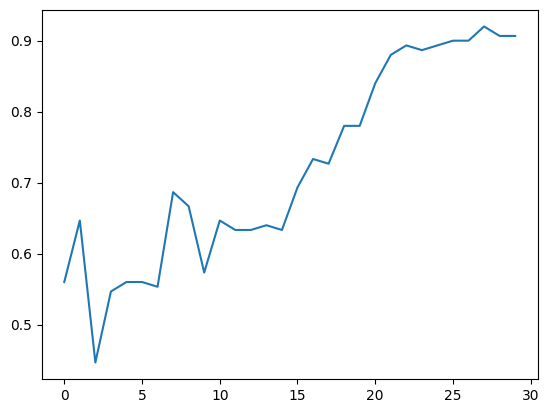

In [64]:
test_accuracy = history.history['val_accuracy']
plt.plot(np.arange(0, 30), test_accuracy)
plt.show()

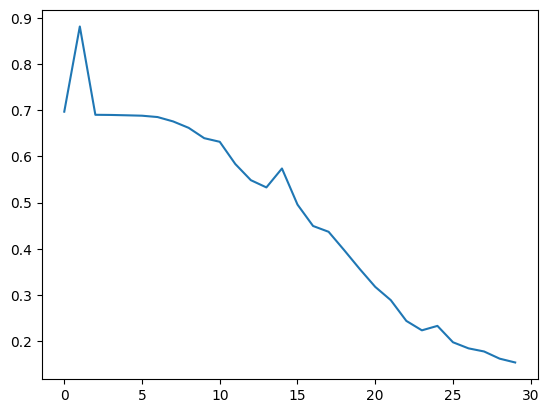

In [66]:
test_accuracy = history.history['loss']
plt.plot(np.arange(0, 30), test_accuracy)
plt.show()

In [67]:
# additional epochs and hidden layers + dropout 
# and MaxPooling instead of AveragePooling + lower batch size
# Build the model
model2 = Sequential()
model2.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=(64,64,1)))
model2.add(layers.MaxPooling2D(pool_size=(2,2)))

model2.add(layers.Conv2D(128, (3,3), activation='relu'))
model2.add(layers.MaxPooling2D(pool_size=(2,2)))

model2.add(layers.Conv2D(256, (3,3), activation='relu'))
model2.add(layers.MaxPooling2D(pool_size=(2,2)))


model2.add(layers.Flatten())
model2.add(layers.Dense(256, activation = 'relu'))
model2.add(layers.Dense(128, activation = 'relu'))
model2.add(layers.Dropout(0.5))
model2.add(layers.Dense(2, activation = 'softmax'))
model2.summary()

# parameterizing
model2.compile("Adam",  loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

# training loop
history = model2.fit(X_train_gray_norm,
                 y_train, 
                 batch_size = 300,
                 epochs = 30,
                 verbose = 1,
                 validation_data=(X_test_gray_norm, Y_test))

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_43 (Conv2D)              │ (None, 62, 62, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 29, 29, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_16 (Flatten)            │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,762,370 (10.54 MB)

 Trainable params: 2,762,370 (10.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 949ms/step - accuracy: 0.5133 - loss: 0.7031 - val_accuracy: 0.4400 - val_loss: 0.7352
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 787ms/step - accuracy: 0.5283 - loss: 0.7031 - val_accuracy: 0.5600 - val_loss: 0.6877
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 809ms/step - accuracy: 0.4917 - loss: 0.6933 - val_accuracy: 0.5600 - val_loss: 0.6879
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 743ms/step - accuracy: 0.5550 - loss: 0.6892 - val_accuracy: 0.5600 - val_loss: 0.6876
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 700ms/step - accuracy: 0.5517 - loss: 0.6887 - val_accuracy: 0.5333 - val_loss: 0.6842
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 701ms/step - accuracy: 0.5750 - loss: 0.6847 - val_accuracy: 0.5733 - val_loss: 0.6781
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 704ms/step - accuracy: 0.5833 - loss: 0.6789 - val_accuracy: 0.6733 - val_loss: 0.6736
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 723ms/step - accuracy: 0.6033 - loss: 0.6681 - val_accuracy: 0.6333 - val_loss:

In [68]:
# Test Accuracy
score = model2.evaluate(X_test_gray_norm, Y_test)
print('Test Accuracy: {}'.format(score[1]))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9200 - loss: 0.1744
Test Accuracy: 0.9200000166893005


# 4

In [69]:
# additional epochs and hidden layers + dropout 
# and MaxPooling instead of AveragePooling + lower batch size
# Build the model
model2 = Sequential()
model2.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=(64,64,1)))
model2.add(layers.MaxPooling2D(pool_size=(2,2)))

model2.add(layers.Conv2D(128, (3,3), activation='relu'))
model2.add(layers.MaxPooling2D(pool_size=(2,2)))

model2.add(layers.Conv2D(256, (3,3), activation='relu'))
model2.add(layers.MaxPooling2D(pool_size=(2,2)))


model2.add(layers.Flatten())
model2.add(layers.Dense(256, activation = 'relu'))
model2.add(layers.Dense(128, activation = 'relu'))
model2.add(layers.Dropout(0.5))
model2.add(layers.Dense(2, activation = 'softmax'))
model2.summary()

# parameterizing
model2.compile("Adam",  loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

# training loop
history = model2.fit(X_train_gray_norm,
                 y_train, 
                 batch_size = 300,
                 epochs = 30,
                 verbose = 1,
                 validation_data=(X_test_gray_norm, Y_test))

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_46 (Conv2D)              │ (None, 62, 62, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 29, 29, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_38 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_17 (Flatten)            │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,762,370 (10.54 MB)

 Trainable params: 2,762,370 (10.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 924ms/step - accuracy: 0.5267 - loss: 0.6921 - val_accuracy: 0.4400 - val_loss: 0.8206
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 799ms/step - accuracy: 0.5250 - loss: 0.7312 - val_accuracy: 0.5600 - val_loss: 0.6800
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 696ms/step - accuracy: 0.5117 - loss: 0.6954 - val_accuracy: 0.5600 - val_loss: 0.6878
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 695ms/step - accuracy: 0.5333 - loss: 0.6902 - val_accuracy: 0.5933 - val_loss: 0.6859
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 691ms/step - accuracy: 0.5733 - loss: 0.6869 - val_accuracy: 0.5933 - val_loss: 0.6797
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 695ms/step - accuracy: 0.6150 - loss: 0.6771 - val_accuracy: 0.5867 - val_loss: 0.6671
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 703ms/step - accuracy: 0.6533 - loss: 0.6612 - val_accuracy: 0.7200 - val_loss: 0.6530
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 734ms/step - accuracy: 0.6900 - loss: 0.6382 - val_accuracy: 0.6533 - val_loss:

In [70]:
# Number of hidden layers and neurons increased and activation function changed to tanh
model3 = Sequential()

model3.add(layers.Conv2D(64, (3,3), activation='relu', input_shape=(64,64,1)))
model3.add(layers.MaxPooling2D((2,2)))

model3.add(layers.Conv2D(128, (3,3), activation='relu'))
model3.add(layers.MaxPooling2D((2,2)))

model3.add(layers.Conv2D(256, (3,3), activation='relu'))
model3.add(layers.MaxPooling2D((2,2)))

model3.add(layers.Flatten())
model3.add(layers.Dense(256, activation='tanh'))
model3.add(layers.Dense(128, activation='tanh'))
model3.add(layers.Dense(64, activation='tanh'))
model3.add(layers.Dense(2, activation='softmax'))

model3.compile("Adam", loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history3 = model3.fit(
    X_train_gray_norm,
    y_train,
    batch_size=300,
    epochs=30,
    validation_data=(X_test_gray_norm, Y_test)
)

# Test Accuracy
score = model3.evaluate(X_test_gray_norm, Y_test)
print('Test Accuracy: {}'.format(score[1]))

Epoch 1/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 968ms/step - accuracy: 0.5000 - loss: 1.7149 - val_accuracy: 0.4400 - val_loss: 0.8496
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 948ms/step - accuracy: 0.5100 - loss: 1.0023 - val_accuracy: 0.5600 - val_loss: 0.7461
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 795ms/step - accuracy: 0.5000 - loss: 0.7369 - val_accuracy: 0.4400 - val_loss: 0.7016
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 905ms/step - accuracy: 0.5000 - loss: 0.6956 - val_accuracy: 0.4400 - val_loss: 0.7121
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 766ms/step - accuracy: 0.5000 - loss: 0.6974 - val_accuracy: 0.4400 - val_loss: 0.7004
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 818ms/step - accuracy: 0.5000 - loss: 0.6949 - val_accuracy: 0.4533 - val_loss: 0.6934
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 893ms/step - accuracy: 0.5233 - loss: 0.6925 - val_accuracy: 0.5533 - val_loss: 0.6915
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 741ms/step - accuracy: 0.5467 - loss: 0.6921 - val_accuracy: 0.6000 - val_loss:

In [71]:
# Number of hidden layers and neurons increased and activation function changed to tanh for both convolutional and dense layers
model4 = Sequential()

model4.add(layers.Conv2D(64, (3,3), activation='tanh', input_shape=(64,64,1)))
model4.add(layers.MaxPooling2D((2,2)))

model4.add(layers.Conv2D(128, (3,3), activation='tanh'))
model4.add(layers.MaxPooling2D((2,2)))

model4.add(layers.Conv2D(256, (3,3), activation='tanh'))
model4.add(layers.MaxPooling2D((2,2)))

model4.add(layers.Flatten())
model4.add(layers.Dense(256, activation='tanh'))
model4.add(layers.Dense(128, activation='tanh'))
model4.add(layers.Dense(64, activation='relu'))
model4.add(layers.Dense(32, activation='relu'))
model4.add(layers.Dense(2, activation='softmax'))

model4.compile("Adam", loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history4 = model4.fit(
    X_train_gray_norm,
    y_train,
    batch_size=300,
    epochs=30,
    validation_data=(X_test_gray_norm, Y_test)
)

# Test Accuracy
score = model4.evaluate(X_test_gray_norm, Y_test)
print('Test Accuracy: {}'.format(score[1]))

Epoch 1/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 891ms/step - accuracy: 0.6217 - loss: 0.6705 - val_accuracy: 0.5600 - val_loss: 0.9163
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 751ms/step - accuracy: 0.5067 - loss: 1.0357 - val_accuracy: 0.4400 - val_loss: 0.7431
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 726ms/step - accuracy: 0.5267 - loss: 0.6939 - val_accuracy: 0.5600 - val_loss: 0.6782
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 866ms/step - accuracy: 0.5033 - loss: 0.6878 - val_accuracy: 0.6133 - val_loss: 0.6830
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 786ms/step - accuracy: 0.5983 - loss: 0.7093 - val_accuracy: 0.5267 - val_loss: 0.6913
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 833ms/step - accuracy: 0.5583 - loss: 0.6764 - val_accuracy: 0.4867 - val_loss: 0.6967
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 892ms/step - accuracy: 0.5233 - loss: 0.6702 - val_accuracy: 0.5467 - val_loss: 0.6695
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 829ms/step - accuracy: 0.5600 - loss: 0.6666 - val_accuracy: 0.5067 - val_loss:

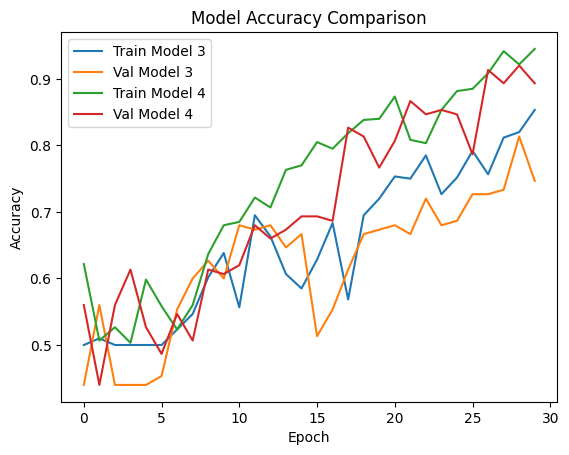

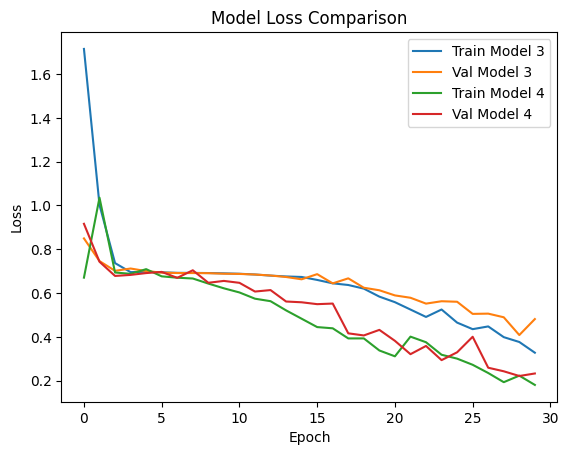

In [72]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history3.history['accuracy'], label='Train Model 3')
plt.plot(history3.history['val_accuracy'], label='Val Model 3')
plt.plot(history4.history['accuracy'], label='Train Model 4')
plt.plot(history4.history['val_accuracy'], label='Val Model 4')
plt.title("Model Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# Loss

plt.plot(history3.history['loss'], label='Train Model 3')
plt.plot(history3.history['val_loss'], label='Val Model 3')
plt.plot(history4.history['loss'], label='Train Model 4')
plt.plot(history4.history['val_loss'], label='Val Model 4')

plt.title("Model Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

The two models show similar behavior with good performance on the test set. Model 3 achieves an accuracy of 0.94, while Model 4 reaches 0.84. The loss for both models decreases during training, which indicates stable learning and convergence.

Model 3 produces the best results even with fewer dense layers. This suggests that a simpler classifier can generalize better for this task. Model 4 contains more dense layers and different activations, which increases model complexity and leads to slightly lower accuracy on the test set.
